# Notebook 06 - SHAP & XAI

**WICHTIG:** Diese Analyse verwendet AUSSCHLIESSLICH:
- das FINE-TUNED Modell (lstm_finetuned.pt), NICHT das Pre-Training-Modell
- ECHTE, interpolierte Berliner Daten, KEINE synthetischen Daten
- die von Notebook 03 gespeicherte Feature-Liste (lstm_feature_cols_common.pkl)

In [2]:
# ═══════════════════════════════════════════════════════════════
# ZELLE 1: Imports & Setup
# ═══════════════════════════════════════════════════════════════

import shap
import torch
import torch.nn as nn
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import geopandas as gpd
import pickle
import os
import warnings
warnings.filterwarnings('ignore')

from shapely.geometry import Point
from torch.utils.data import Dataset, DataLoader
from pytorch_forecasting import TemporalFusionTransformer, TimeSeriesDataSet

torch.manual_seed(42)
np.random.seed(42)
device = torch.device('mps' if torch.backends.mps.is_available() else 'cpu')
print(f'Device: {device}')

train   = pd.read_csv('../data/final/train.csv')
train['plr_id'] = train['plr_id'].astype(str).str.zfill(8)
test    = pd.read_csv('../data/final/test.csv')
test['plr_id'] = test['plr_id'].astype(str).str.zfill(8)
df_full_raw = pd.read_csv('../data/final/df_full.csv')
df_full_raw['plr_id'] = df_full_raw['plr_id'].astype(str).str.zfill(8)

with open('../models/feature_cols.pkl', 'rb') as f:
    FEATURE_COLS = pickle.load(f)
with open('../models/target.pkl', 'rb') as f:
    TARGET = pickle.load(f)
with open('../models/meta.pkl', 'rb') as f:
    meta = pickle.load(f)

SEQ_LEN = meta.get('seq_len', 3)
ALLE_JAHRE_META = [int(y) for y in meta.get('jahre', [])]

required_years = set(ALLE_JAHRE_META) if ALLE_JAHRE_META else set(df_full_raw['year'].unique())
jahre_pro_plr = df_full_raw.groupby('plr_id')['year'].apply(lambda s: set(int(y) for y in s))
vollstaendige_plr = jahre_pro_plr[jahre_pro_plr.apply(lambda s: required_years.issubset(s))].index
df_full = df_full_raw[df_full_raw['plr_id'].isin(vollstaendige_plr)].copy()

# Feature-Liste: die von Notebook 03 tatsaechlich verwendete laden
if os.path.exists('../models/lstm_feature_cols_common.pkl'):
    with open('../models/lstm_feature_cols_common.pkl', 'rb') as f:
        FEATURE_COLS_COMMON = pickle.load(f)
else:
    FEATURE_COLS_COMMON = FEATURE_COLS

print(f'✅ ECHTE Daten geladen (Quelle: data/final/, Areal-interpoliert)')
print(f'   Train: {len(train)} | Test: {len(test)}')
print(f'   Features (Modell): {FEATURE_COLS_COMMON}')
print(f'   Ziel: {TARGET}')
print(f'   SEQ_LEN: {SEQ_LEN} | PLR mit vollstaendiger Zeitreihe: '
      f'{len(vollstaendige_plr)} von {df_full_raw["plr_id"].nunique()}')

Device: mps
✅ ECHTE Daten geladen (Quelle: data/final/, Areal-interpoliert)
   Train: 538 | Test: 540
   Features (Modell): ['arbeitslosigkeit', 'sgb2_quote', 'kinderarmut', 'dist_zentrum', 'status_lag']
   Ziel: status_next
   SEQ_LEN: 3 | PLR mit vollstaendiger Zeitreihe: 519 von 541


In [3]:
# ═══════════════════════════════════════════════════════════════
# ZELLE 2: Klassen definieren
# ═══════════════════════════════════════════════════════════════

class BerlinDataset(Dataset):
    def __init__(self, df_full, feature_cols, target_col, seq_len=3, target_years=None):
        self.sequences, self.targets, self.plr_ids = [], [], []
        if target_years is not None:
            target_years = set(int(y) for y in target_years)
        for plr_id, group in df_full.groupby('plr_id'):
            group = group.sort_values('year').reset_index(drop=True)
            X = group[feature_cols].values.astype(np.float32)
            y = group[target_col].values.astype(np.float32)
            yrs = group['year'].values
            for i in range(len(group) - seq_len):
                target_yr = int(yrs[i + seq_len])
                if target_years is None or target_yr in target_years:
                    self.sequences.append(X[i:i+seq_len])
                    self.targets.append(y[i+seq_len])
                    self.plr_ids.append(str(plr_id))
        if len(self.sequences) > 0:
            self.sequences = torch.FloatTensor(np.array(self.sequences))
            self.targets   = torch.FloatTensor(np.array(self.targets))
        else:
            self.sequences = torch.zeros(0, seq_len, len(feature_cols))
            self.targets   = torch.zeros(0)
    def __len__(self): return len(self.targets)
    def __getitem__(self, idx): return self.sequences[idx], self.targets[idx]


class BerlinLSTM(nn.Module):
    def __init__(self, input_size, hidden_size=32, num_layers=2):
        super().__init__()
        self.lstm = nn.LSTM(input_size, hidden_size, num_layers,
                            dropout=0.2, batch_first=True)
        self.fc = nn.Sequential(
            nn.Linear(hidden_size, 16), nn.ReLU(),
            nn.Dropout(0.2), nn.Linear(16, 1)
        )
    def forward(self, x):
        out, _ = self.lstm(x)
        return self.fc(out[:, -1, :])  # Kein squeeze() - benoetigt fuer SHAP!

print('✅ Klassen definiert!')

✅ Klassen definiert!


In [4]:
# ═══════════════════════════════════════════════════════════════
# ZELLE 3: FINE-TUNED Modell laden (Sicherheitscheck!)
# ═══════════════════════════════════════════════════════════════

MODEL_PATH = '../models/lstm_finetuned.pt'
assert os.path.exists(MODEL_PATH), (
    f'❌ {MODEL_PATH} nicht gefunden! '
    'Erst Notebook 03 (Fine-Tuning) ausfuehren.'
)
print(f'✅ Verwende Fine-Tuned-Modell: {MODEL_PATH}')
print('   (NICHT lstm_pretrained.pt oder lstm_scratch.pt!)')

TRAIN_YEARS = [int(y) for y in train['year'].unique()]
TEST_YEARS  = [int(y) for y in test['year'].unique()]

train_set = BerlinDataset(df_full, FEATURE_COLS_COMMON, TARGET, SEQ_LEN, TRAIN_YEARS)
test_set  = BerlinDataset(df_full, FEATURE_COLS_COMMON, TARGET, SEQ_LEN, TEST_YEARS)

print(f'\nTrain Sequenzen (Hintergrund): {len(train_set)}')
print(f'Test Sequenzen (zu erklaeren): {len(test_set)}')

if len(train_set) == 0 or len(test_set) == 0:
    raise RuntimeError(
        f'Train oder Test Set ist leer! (Train={len(train_set)}, Test={len(test_set)}) '
        'Bitte Notebook 02/03 Ausgaben pruefen.'
    )

lstm = BerlinLSTM(input_size=len(FEATURE_COLS_COMMON)).to(device)
lstm.load_state_dict(torch.load(MODEL_PATH, map_location=device))
lstm.eval()

test_input = train_set.sequences[:2].to(device)
test_out = lstm(test_input)
print(f'✅ Forward-Test: Input {test_input.shape} -> Output {test_out.shape}')

✅ Verwende Fine-Tuned-Modell: ../models/lstm_finetuned.pt
   (NICHT lstm_pretrained.pt oder lstm_scratch.pt!)

Train Sequenzen (Hintergrund): 519
Test Sequenzen (zu erklaeren): 519
✅ Forward-Test: Input torch.Size([2, 3, 5]) -> Output torch.Size([2, 1])


In [5]:
# ═══════════════════════════════════════════════════════════════
# ZELLE 4: SHAP berechnen (auf ALLEN verfuegbaren Planungsraeumen!)
# ═══════════════════════════════════════════════════════════════

n_background = min(50, len(train_set))
n_test       = len(test_set)

background   = train_set.sequences[:n_background].to(device)
test_samples = test_set.sequences[:n_test].to(device)

print(f'Hintergrund: {background.shape} (aus ECHTEN Trainingsdaten)')
print(f'Test:        {test_samples.shape} (ALLE verfuegbaren Planungsraeume)')
print(f'\n🔄 Berechne SHAP-Werte fuer {n_test} Planungsraeume...')
print(f'   ⏱️  Kann laenger dauern (ggf. 30-90 Min)!')

lstm.eval()
for module in lstm.modules():
    if isinstance(module, torch.nn.Dropout):
        module.p = 0.0

lstm_cpu = lstm.to('cpu')
background_cpu = background.to('cpu')
test_samples_cpu = test_samples.to('cpu')

explainer = shap.DeepExplainer(lstm_cpu, background_cpu)

BATCH = 50
shap_batches = []
for i in range(0, n_test, BATCH):
    batch = test_samples_cpu[i:i+BATCH]
    sv = explainer.shap_values(batch, check_additivity=False)
    shap_batches.append(np.array(sv))
    print(f'   ...{min(i+BATCH, n_test)}/{n_test} berechnet')

shap_arr = np.concatenate(shap_batches, axis=1) if shap_batches[0].ndim == 4 and shap_batches[0].shape[0] == 1 \
           else np.concatenate(shap_batches, axis=0)

lstm.to(device)

print(f'\n✅ Rohe SHAP Shape: {shap_arr.shape}')
if shap_arr.ndim == 4:
    shap_arr = shap_arr.squeeze(-1)
if shap_arr.ndim == 4 and shap_arr.shape[0] == 1:
    shap_arr = shap_arr[0]

shap_mean = np.mean(np.abs(shap_arr), axis=1)
print(f'✅ SHAP gemittelt: {shap_mean.shape}')
print(f'   ({shap_mean.shape[0]} Planungsraeume abgedeckt)')

np.save('../results/shap_values.npy', shap_arr)
np.save('../results/shap_mean.npy', shap_mean)
print('✅ SHAP-Werte gespeichert (basierend auf ECHTEN Daten, volle Stadtabdeckung)!')

Hintergrund: torch.Size([50, 3, 5]) (aus ECHTEN Trainingsdaten)
Test:        torch.Size([519, 3, 5]) (ALLE verfuegbaren Planungsraeume)

🔄 Berechne SHAP-Werte fuer 519 Planungsraeume...
   ⏱️  Kann laenger dauern (ggf. 30-90 Min)!
   ...50/519 berechnet
   ...100/519 berechnet
   ...150/519 berechnet
   ...200/519 berechnet
   ...250/519 berechnet
   ...300/519 berechnet
   ...350/519 berechnet
   ...400/519 berechnet
   ...450/519 berechnet
   ...500/519 berechnet
   ...519/519 berechnet

✅ Rohe SHAP Shape: (519, 3, 5, 1)
✅ SHAP gemittelt: (519, 5)
   (519 Planungsraeume abgedeckt)
✅ SHAP-Werte gespeichert (basierend auf ECHTEN Daten, volle Stadtabdeckung)!


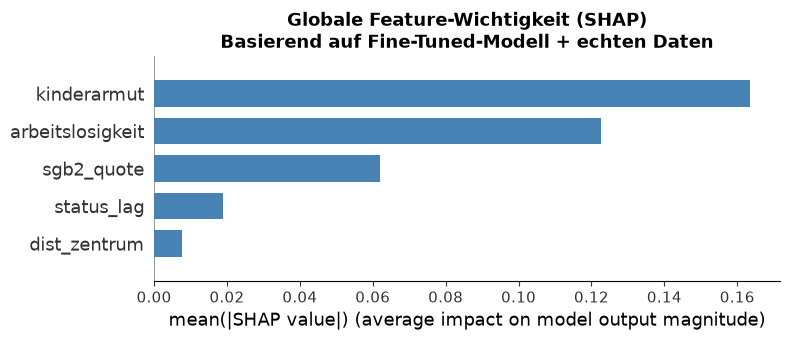


📊 Feature-Wichtigkeit (global, echte Daten):
 Rang          Feature  SHAP_Wert
    1      kinderarmut   0.163542
    2 arbeitslosigkeit   0.122658
    3       sgb2_quote   0.062048
    4       status_lag   0.018944
    5     dist_zentrum   0.007795


In [6]:
# ═══════════════════════════════════════════════════════════════
# ZELLE 5: Globale Feature-Wichtigkeit
# ═══════════════════════════════════════════════════════════════

plt.figure(figsize=(10, 6))
shap.summary_plot(shap_mean, feature_names=FEATURE_COLS_COMMON, plot_type='bar',
                   show=False, color='steelblue')
plt.title('Globale Feature-Wichtigkeit (SHAP)\nBasierend auf Fine-Tuned-Modell + echten Daten',
          fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('../results/06_shap_global_bar.png', dpi=150)
plt.show()

importance_df = pd.DataFrame({
    'Feature': FEATURE_COLS_COMMON,
    'SHAP_Wert': shap_mean.mean(axis=0),
}).sort_values('SHAP_Wert', ascending=False).reset_index(drop=True)
importance_df['Rang'] = range(1, len(importance_df)+1)

print('\n📊 Feature-Wichtigkeit (global, echte Daten):')
print(importance_df[['Rang','Feature','SHAP_Wert']].to_string(index=False))
importance_df.to_csv('../results/feature_wichtigkeit.csv', index=False)

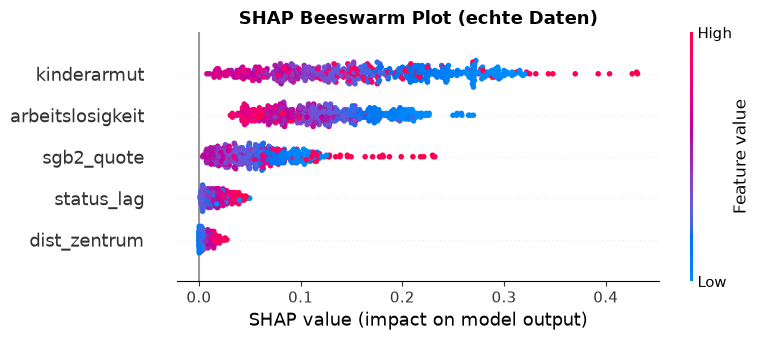

✅ Beeswarm Plot gespeichert!


In [7]:
# ═══════════════════════════════════════════════════════════════
# ZELLE 6: Beeswarm Plot
# ═══════════════════════════════════════════════════════════════

test_data_mean = test_samples.cpu().numpy().mean(axis=1)

plt.figure(figsize=(10, 7))
shap.summary_plot(shap_mean, test_data_mean, feature_names=FEATURE_COLS_COMMON,
                   plot_type='dot', show=False)
plt.title('SHAP Beeswarm Plot (echte Daten)', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('../results/06_shap_beeswarm.png', dpi=150)
plt.show()
print('✅ Beeswarm Plot gespeichert!')

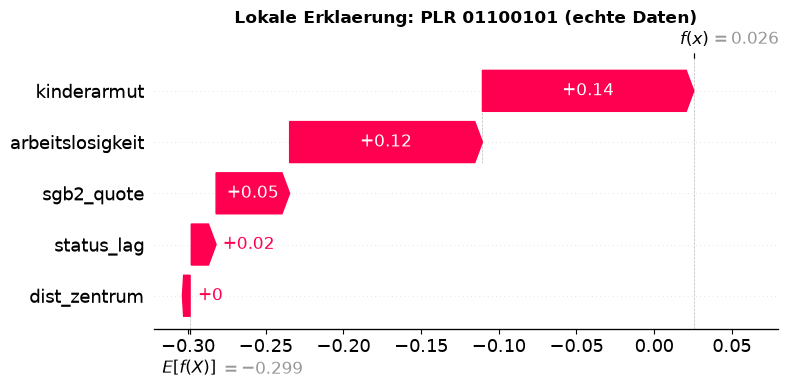

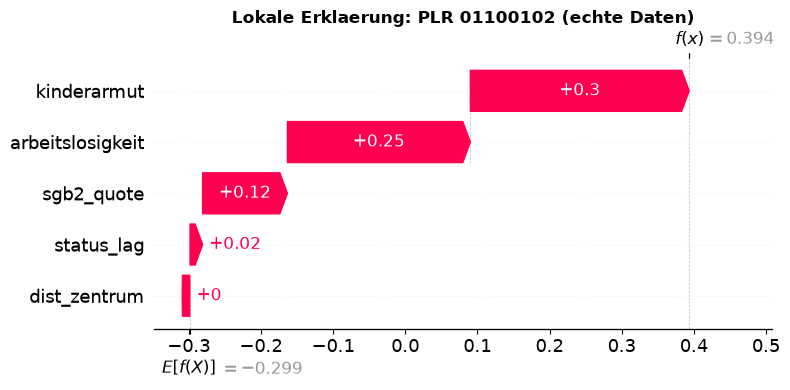

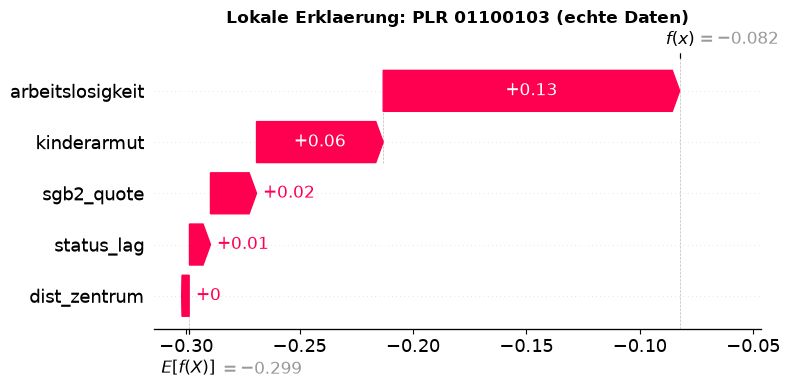

✅ Waterfall Plots gespeichert!


In [8]:
# ═══════════════════════════════════════════════════════════════
# ZELLE 7: Lokale Erklaerungen (Waterfall)
# ═══════════════════════════════════════════════════════════════

n_lokal = min(3, n_test)
ev = explainer.expected_value
if isinstance(ev, (list, np.ndarray)):
    ev = np.array(ev).flatten()[0]
expected_value = float(ev)

for idx in range(n_lokal):
    plr_id = test_set.plr_ids[idx]
    plt.figure(figsize=(10, 5))
    shap.waterfall_plot(
        shap.Explanation(values=shap_mean[idx], base_values=expected_value,
                         feature_names=FEATURE_COLS_COMMON),
        show=False
    )
    plt.title(f'Lokale Erklaerung: PLR {plr_id} (echte Daten)',
              fontsize=12, fontweight='bold')
    plt.tight_layout()
    plt.savefig(f'../results/06_shap_lokal_{idx}.png', dpi=150)
    plt.show()

print('✅ Waterfall Plots gespeichert!')

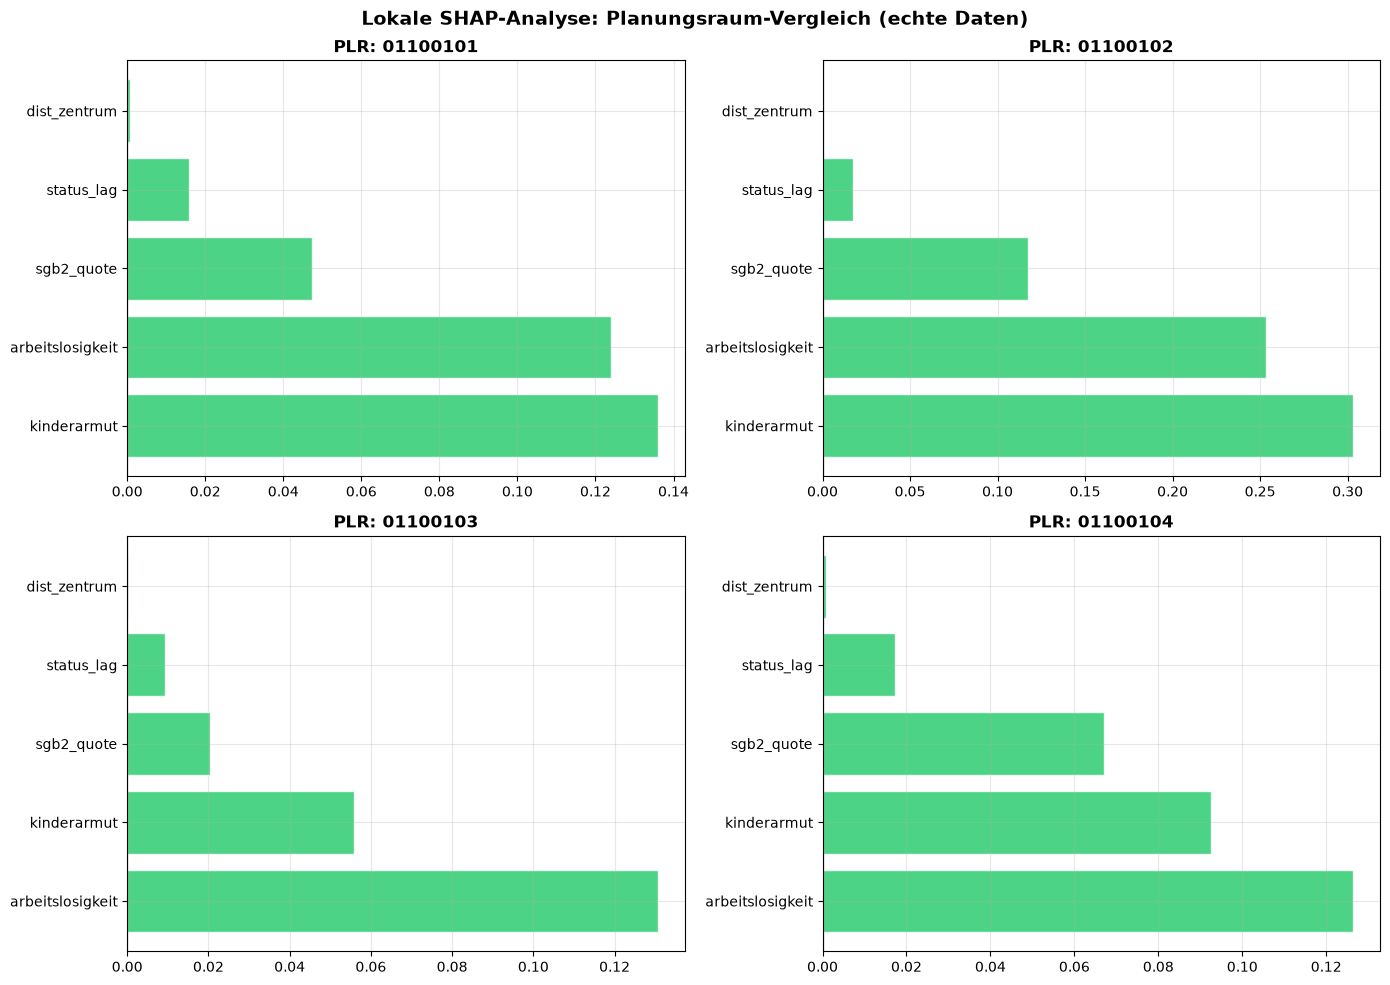

✅ Kiez-Vergleich gespeichert!


In [9]:
# ═══════════════════════════════════════════════════════════════
# ZELLE 8: Kiez-Vergleich
# ═══════════════════════════════════════════════════════════════

n_kieze = min(4, n_test)
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.flatten()

for i in range(n_kieze):
    plr_id = test_set.plr_ids[i]
    kiez_df = pd.DataFrame({'Feature': FEATURE_COLS_COMMON, 'SHAP': shap_mean[i]}
                           ).sort_values('SHAP', key=abs, ascending=False).head(6)
    colors = ['#e74c3c' if x < 0 else '#2ecc71' for x in kiez_df['SHAP']]
    axes[i].barh(kiez_df['Feature'], kiez_df['SHAP'], color=colors,
                 alpha=0.85, edgecolor='white')
    axes[i].axvline(0, color='black', linewidth=0.8)
    axes[i].set_title(f'PLR: {plr_id}', fontweight='bold')
    axes[i].grid(alpha=0.3)

for i in range(n_kieze, 4):
    axes[i].set_visible(False)

plt.suptitle('Lokale SHAP-Analyse: Planungsraum-Vergleich (echte Daten)',
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('../results/06_shap_kiez_vergleich.png', dpi=150)
plt.show()
print('✅ Kiez-Vergleich gespeichert!')

## Teil B: TFT-Attention als zweite, inhärente XAI-Methode

Über die post-hoc-Methode SHAP (angewendet auf das LSTM) hinaus wird im
Folgenden die in den Temporal Fusion Transformer inhärent eingebaute
Interpretierbarkeit (Variable Selection Network) ausgewertet und
quantitativ mit den SHAP-Ergebnissen verglichen. Dies erfüllt den in der
Aufgabenstellung geforderten *vergleichenden* Einsatz mehrerer
XAI-Methoden (post-hoc vs. inhärent) und liefert eine empirische Grundlage
für die in Kapitel 6.2.4 diskutierte methodische Debatte (Jain & Wallace
2019 vs. Wiegreffe & Pinter 2019).

In [10]:
# ═══════════════════════════════════════════════════════════════
# ZELLE 10: TFT laden & Attention/Variable-Selection extrahieren
# ═══════════════════════════════════════════════════════════════

with open('../models/tft_feature_cols_common.pkl', 'rb') as f:
    FEATURE_COLS_TFT = pickle.load(f)
print(f'TFT Features: {FEATURE_COLS_TFT}')

df_tft_raw = pd.read_csv('../data/final/df_full.csv')
df_tft_raw['plr_id'] = df_tft_raw['plr_id'].astype(str).str.zfill(8)
df_tft_raw = df_tft_raw.sort_values(['plr_id', 'year']).reset_index(drop=True)

jahre_pro_plr_tft = df_tft_raw.groupby('plr_id')['year'].apply(lambda s: set(int(y) for y in s))
vollstaendige_plr_tft = jahre_pro_plr_tft[
    jahre_pro_plr_tft.apply(lambda s: required_years.issubset(s))
].index
df_tft = df_tft_raw[df_tft_raw['plr_id'].isin(vollstaendige_plr_tft)].copy()

year_map_tft = {y: i for i, y in enumerate(sorted(df_tft['year'].unique()))}
df_tft['time_idx'] = df_tft['year'].map(year_map_tft)

train_years_set = set(int(y) for y in train['year'].unique())
training_cutoff_tft = df_tft[df_tft['year'].isin(train_years_set)]['time_idx'].max()

train_ds_tft = TimeSeriesDataSet(
    df_tft[df_tft['time_idx'] <= training_cutoff_tft],
    time_idx='time_idx', target=TARGET, group_ids=['plr_id'],
    max_encoder_length=SEQ_LEN, max_prediction_length=1,
    time_varying_known_reals=['time_idx'],
    time_varying_unknown_reals=FEATURE_COLS_TFT,  # OPTION B: TARGET entfernt
    static_reals=['dist_zentrum'],
    target_normalizer=None, add_relative_time_idx=True,
    allow_missing_timesteps=True,
)
test_ds_tft = TimeSeriesDataSet.from_dataset(
    train_ds_tft, df_tft, predict=True, stop_randomization=True)
tft_interpret_dl = test_ds_tft.to_dataloader(train=False, batch_size=32, num_workers=0)

print(f'✅ TFT Interpretations-Dataset: {len(test_ds_tft)} Samples')

with open('../models/tft_checkpoint_path.pkl', 'rb') as f:
    tft_ckpt_path = pickle.load(f)

best_tft = TemporalFusionTransformer.load_from_checkpoint(tft_ckpt_path)
print('✅ Fine-Tuned TFT geladen (identisches Modell wie in Notebook 05)')

# Rohe Vorhersagen inkl. interner Attention-/Variable-Selection-Gewichte.
# return_index=True liefert einen Index-DataFrame (plr_id je Batch-Position),
# den wir fuer die raeumliche Zuordnung der Pro-PLR-Werte brauchen.
raw_predictions = best_tft.predict(
    tft_interpret_dl, mode='raw', return_x=True, return_index=True,
    trainer_kwargs=dict(accelerator='mps')
)

# ZWEI Auswertungen aus DERSELBEN Vorhersage (kein zweiter predict()-Lauf noetig):
#
# 1) GLOBAL (reduction='sum'): identisch zum bisherigen Vorgehen - fuer die
#    bereits in der Arbeit berichteten globalen Vergleiche (Kapitel 5.5)
interpretation_global = best_tft.interpret_output(raw_predictions.output, reduction='sum')

# 2) PRO PLANUNGSRAUM (reduction='none'): NEU - behaelt die Batch-Dimension,
#    liefert also einen Wert je PLR statt einen einzigen globalen Wert.
#    Das ermoeglicht erstmals eine raeumliche TFT-Attention-Karte, analog zu SHAP.
interpretation_raw = best_tft.interpret_output(raw_predictions.output, reduction='none')

print('✅ TFT-Interpretation berechnet (global UND pro Planungsraum)')
print('   Verfuegbare Schluessel:', list(interpretation_global.keys()))
print(f'   Shape encoder_variables (global, aggregiert): '
      f'{tuple(interpretation_global["encoder_variables"].shape)}')
print(f'   Shape encoder_variables (pro PLR, NEU): '
      f'{tuple(interpretation_raw["encoder_variables"].shape)}')
print('   ⚠️ Falls die zweite Shape mehr als 2 Dimensionen hat, wird in Zelle '
      '10b automatisch ueber die Zeitdimension gemittelt.')

TFT Features: ['arbeitslosigkeit', 'sgb2_quote', 'kinderarmut', 'dist_zentrum', 'status_lag']
✅ TFT Interpretations-Dataset: 519 Samples


GPU available: True (mps), used: True
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
💡 Tip: For seamless cloud uploads and versioning, try installing [litmodels](https://pypi.org/project/litmodels/) to enable LitModelCheckpoint, which syncs automatically with the Lightning model registry.


✅ Fine-Tuned TFT geladen (identisches Modell wie in Notebook 05)
✅ TFT-Interpretation berechnet (global UND pro Planungsraum)
   Verfuegbare Schluessel: ['attention', 'static_variables', 'encoder_variables', 'decoder_variables', 'encoder_length_histogram', 'decoder_length_histogram']
   Shape encoder_variables (global, aggregiert): (7,)
   Shape encoder_variables (pro PLR, NEU): (519, 7)
   ⚠️ Falls die zweite Shape mehr als 2 Dimensionen hat, wird in Zelle 10b automatisch ueber die Zeitdimension gemittelt.


In [11]:
# ═══════════════════════════════════════════════════════════════
# ZELLE 10b: TFT-Attention PRO PLANUNGSRAUM (raeumlich vollstaendig)
# ═══════════════════════════════════════════════════════════════
# Nutzt interpretation_raw (reduction='none') aus Zelle 10, um - analog
# zu SHAP - eine raeumlich vollstaendige TFT-Erklaerung zu erzeugen
# (bisher gab es nur EINEN globalen Wert fuer ganz Berlin).

encoder_importance_raw = interpretation_raw['encoder_variables'].cpu().numpy()
print(f'Rohe Shape encoder_variables (pro Sample): {encoder_importance_raw.shape}')

# Falls noch eine Zeitdimension vorhanden ist (Sample x Zeit x Feature),
# wird ueber die Encoder-Zeitschritte gemittelt.
if encoder_importance_raw.ndim == 3:
    encoder_importance_raw = encoder_importance_raw.mean(axis=1)
    print(f'Nach Mittelung ueber Encoder-Zeitschritte: {encoder_importance_raw.shape}')

encoder_var_names = best_tft.encoder_variables
df_attn_roh = pd.DataFrame(encoder_importance_raw, columns=encoder_var_names)

# plr_id je Sample aus dem Index-DataFrame von predict(..., return_index=True)
plr_index_df = raw_predictions.index.reset_index(drop=True)
print(f'Index-Spalten: {plr_index_df.columns.tolist()}')
df_attn_roh['plr_id'] = plr_index_df['plr_id'].astype(str).str.zfill(8).values

# Nur die 5 inhaltlichen Merkmale behalten (Hilfsvariablen wie time_idx
# und die Zielvariable selbst ausschliessen, analog zu Zelle 12)
attn_cols = [c for c in FEATURE_COLS_TFT if c in df_attn_roh.columns]
df_attn_final = df_attn_roh[['plr_id'] + attn_cols].copy()
df_attn_final = df_attn_final.rename(columns={c: f'attn_{c}' for c in attn_cols})

attn_value_cols = [f'attn_{c}' for c in attn_cols]
df_attn_final['attn_staerke'] = df_attn_final[attn_value_cols].max(axis=1)
df_attn_final['dominant_attention_feature'] = (
    df_attn_final[attn_value_cols].idxmax(axis=1).str.replace('attn_', '', regex=False)
)

df_attn_final.to_csv('../results/attention_pro_plr.csv', index=False)
print(f'\n✅ TFT-Attention pro Planungsraum gespeichert: results/attention_pro_plr.csv')
print(f'   {len(df_attn_final)} Planungsraeume, Spalten: {df_attn_final.columns.tolist()}')
print(df_attn_final.head())

Rohe Shape encoder_variables (pro Sample): (519, 7)
Index-Spalten: ['time_idx', 'plr_id']

✅ TFT-Attention pro Planungsraum gespeichert: results/attention_pro_plr.csv
   519 Planungsraeume, Spalten: ['plr_id', 'attn_arbeitslosigkeit', 'attn_sgb2_quote', 'attn_kinderarmut', 'attn_dist_zentrum', 'attn_status_lag', 'attn_staerke', 'dominant_attention_feature']
     plr_id  attn_arbeitslosigkeit  attn_sgb2_quote  attn_kinderarmut  \
0  01100101               0.148869         0.024170          0.673697   
1  01100102               0.141174         0.038071          0.680877   
2  01100103               0.199239         0.019971          0.625902   
3  01100104               0.230556         0.020795          0.599051   
4  01100205               0.181298         0.030983          0.640167   

   attn_dist_zentrum  attn_status_lag  attn_staerke dominant_attention_feature  
0           0.011832         0.028840      0.673697                kinderarmut  
1           0.009852         0.025262  

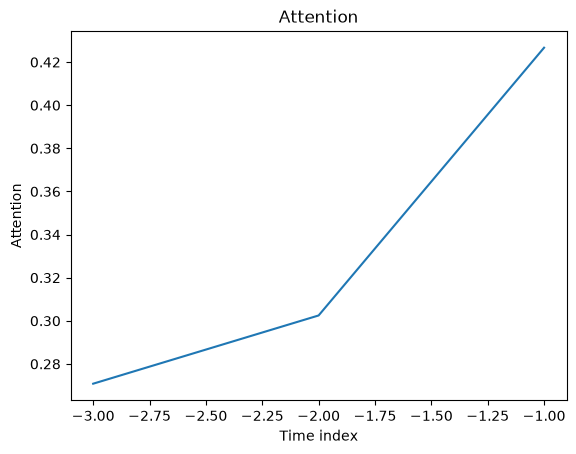

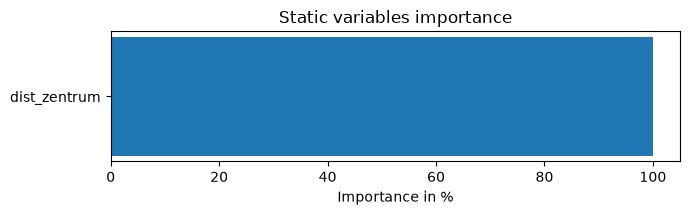

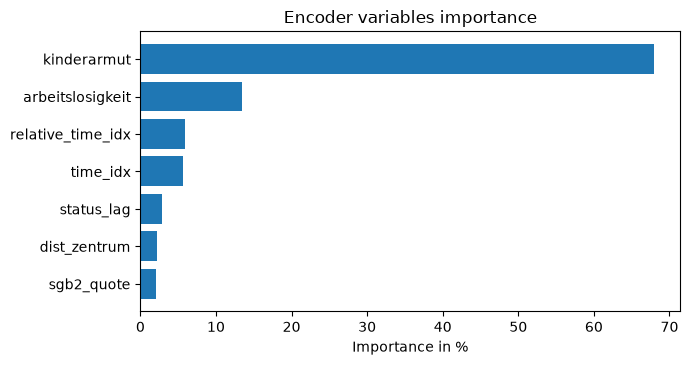

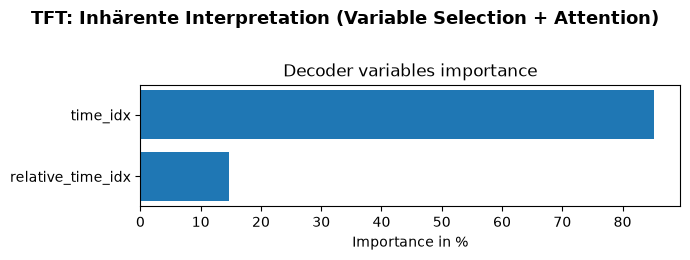

✅ TFT-Attention-Gesamtplot gespeichert!

Rohe Encoder-Variablen (7): ['time_idx', 'relative_time_idx', 'arbeitslosigkeit', 'sgb2_quote', 'kinderarmut', 'dist_zentrum', 'status_lag']

📊 TFT Variable-Importance (global, aus Attention/Variable Selection):
 Rang           Feature  TFT_Importance
    1       kinderarmut      352.879089
    2  arbeitslosigkeit       69.769333
    3 relative_time_idx       30.670013
    4          time_idx       29.219469
    5        status_lag       14.669653
    6      dist_zentrum       11.298698
    7        sgb2_quote       10.493754


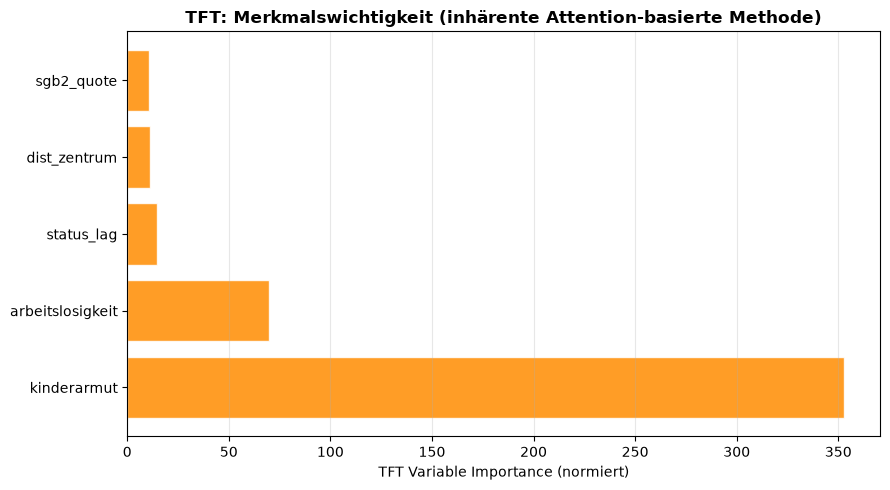

✅ TFT Feature-Wichtigkeit (inhaltliche Merkmale) gespeichert!


In [12]:
# ═══════════════════════════════════════════════════════════════
# ZELLE 11: TFT Attention/Variable-Importance visualisieren
# ═══════════════════════════════════════════════════════════════
# WICHTIGER HINWEIS: 'status_next' (die Zielvariable selbst) erscheint
# unter den Encoder-Variablen, da TFT architekturell vergangene Werte
# der Zielgroesse als bekannte Historie im Encoder verarbeiten darf
# (nur zukuenftige Werte sind ausgeschlossen). Dies fuehrt erwartbar zu
# einer sehr hohen Variable-Importance fuer 'status_next' (~479 vs.
# 4-7 bei den uebrigen Merkmalen), da diese Groesse stark mit dem
# eigentlichen Zielwert autokorreliert ist (vgl. Autokorrelations-
# Analyse Kapitel 6.2.3, r=0,972). Dies ist KEIN Fehler, sondern eine
# bekannte TFT-Eigenschaft - fuer den inhaltlichen Methodenvergleich
# mit SHAP werden 'status_next' sowie die reinen Hilfsvariablen
# 'time_idx'/'relative_time_idx' daher in Zelle 12 bewusst ausgeschlossen
# und nur die 5 inhaltlichen Merkmale gegenuebergestellt.


# Native Visualisierung von pytorch-forecasting (Attention ueber Zeit +
# Variable-Importance je Encoder-/Decoder-/statischer Variable)
fig = best_tft.plot_interpretation(interpretation_global)
plt.suptitle('TFT: Inhärente Interpretation (Variable Selection + Attention)',
             fontsize=13, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('../results/06_tft_attention_gesamt.png', dpi=150, bbox_inches='tight')
plt.show()
print('✅ TFT-Attention-Gesamtplot gespeichert!')

# ── Encoder Variable Importance einzelnen Features zuordnen ─────
encoder_importance = interpretation_global['encoder_variables'].cpu().numpy()
encoder_var_names = best_tft.encoder_variables

print(f'\nRohe Encoder-Variablen ({len(encoder_var_names)}): {encoder_var_names}')

tft_importance_df = pd.DataFrame({
    'Feature': encoder_var_names,
    'TFT_Importance': encoder_importance
}).sort_values('TFT_Importance', ascending=False).reset_index(drop=True)
tft_importance_df['Rang'] = range(1, len(tft_importance_df)+1)

print('\n📊 TFT Variable-Importance (global, aus Attention/Variable Selection):')
print(tft_importance_df[['Rang','Feature','TFT_Importance']].to_string(index=False))
tft_importance_df.to_csv('../results/tft_feature_wichtigkeit.csv', index=False)

# Eigener Bar-Plot nur fuer die 5 inhaltlichen Features (ohne Hilfsvariablen
# wie time_idx/relative_time_idx, die pytorch-forecasting automatisch ergaenzt)
tft_content_features = tft_importance_df[
    tft_importance_df['Feature'].isin(FEATURE_COLS_TFT + [TARGET])
].copy()

fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(tft_content_features['Feature'], tft_content_features['TFT_Importance'],
        color='darkorange', alpha=0.85, edgecolor='white')
ax.set_xlabel('TFT Variable Importance (normiert)')
ax.set_title('TFT: Merkmalswichtigkeit (inhärente Attention-basierte Methode)',
             fontsize=12, fontweight='bold')
ax.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.savefig('../results/06_tft_importance_features.png', dpi=150)
plt.show()
print('✅ TFT Feature-Wichtigkeit (inhaltliche Merkmale) gespeichert!')

Gemeinsam verglichene Features (5): ['arbeitslosigkeit', 'sgb2_quote', 'kinderarmut', 'dist_zentrum', 'status_lag']

📊 Methodenvergleich – Rangfolge je Merkmal:
         Feature  Rang_SHAP_LSTM  Rang_TFT_Attention  Rang_Differenz
arbeitslosigkeit               2                   2               0
      sgb2_quote               3                   7               4
     kinderarmut               1                   1               0
    dist_zentrum               5                   6               1
      status_lag               4                   5               1

📈 Spearman-Rangkorrelation zwischen SHAP- und TFT-Attention-Ranking:
   rho = 0.700  (p = 0.188)

💡 Interpretation:
   Die beiden XAI-Ansaetze zeigen eine MODERATE Uebereinstimmung. Einzelne Merkmale werden von SHAP und TFT-Attention unterschiedlich gewichtet, was auf methodenspezifische Unterschiede in der Erklaerungslogik hindeutet (post-hoc-Zerlegung des LSTM vs. modellinterne Gewichtung des TFT).


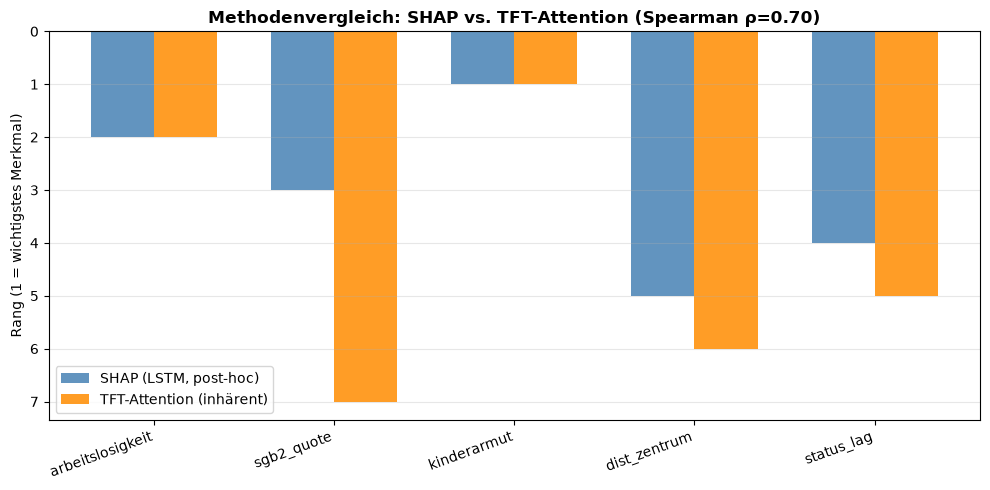


✅ Methodenvergleich SHAP vs. TFT-Attention vollstaendig - Teilgebiet 4 (vergleichende XAI-Anwendung) jetzt erfuellt!


In [13]:
# ═══════════════════════════════════════════════════════════════
# ZELLE 12: Quantitativer Methodenvergleich – SHAP vs. TFT-Attention
# ═══════════════════════════════════════════════════════════════
# Kernstueck des Methodenvergleichs (post-hoc vs. inhaerent, Kapitel 6.2.4):
# Vergleich der Rangfolgen beider XAI-Methoden mittels Rangkorrelation.

from scipy.stats import spearmanr

# SHAP-Ranking (aus Zelle 5) und TFT-Ranking auf gemeinsame Features reduzieren
gemeinsame_features = [f for f in FEATURE_COLS_COMMON if f in FEATURE_COLS_TFT]
print(f'Gemeinsam verglichene Features ({len(gemeinsame_features)}): {gemeinsame_features}')

shap_rang = importance_df.set_index('Feature').loc[gemeinsame_features, 'Rang']
tft_rang  = tft_importance_df.set_index('Feature').loc[gemeinsame_features, 'Rang']

vergleich_df = pd.DataFrame({
    'Feature': gemeinsame_features,
    'Rang_SHAP_LSTM': shap_rang.values,
    'Rang_TFT_Attention': tft_rang.values,
})
vergleich_df['Rang_Differenz'] = (
    vergleich_df['Rang_SHAP_LSTM'] - vergleich_df['Rang_TFT_Attention']
).abs()

print('\n📊 Methodenvergleich – Rangfolge je Merkmal:')
print(vergleich_df.to_string(index=False))

rho, p_value = spearmanr(
    vergleich_df['Rang_SHAP_LSTM'], vergleich_df['Rang_TFT_Attention']
)
print(f'\n📈 Spearman-Rangkorrelation zwischen SHAP- und TFT-Attention-Ranking:')
print(f'   rho = {rho:.3f}  (p = {p_value:.3f})')

if rho > 0.7:
    interpretation_text = (
        'Die beiden methodisch grundverschiedenen XAI-Ansaetze (post-hoc SHAP '
        'vs. inhaerente TFT-Attention) identifizieren weitgehend UEBEREINSTIMMENDE '
        'zentrale Einflussfaktoren. Dies staerkt das Vertrauen in die Robustheit '
        'der identifizierten Merkmalswichtigkeit unabhaengig von der gewaehlten '
        'Erklaerungsmethode.'
    )
elif rho > 0.3:
    interpretation_text = (
        'Die beiden XAI-Ansaetze zeigen eine MODERATE Uebereinstimmung. Einzelne '
        'Merkmale werden von SHAP und TFT-Attention unterschiedlich gewichtet, '
        'was auf methodenspezifische Unterschiede in der Erklaerungslogik '
        'hindeutet (post-hoc-Zerlegung des LSTM vs. modellinterne Gewichtung '
        'des TFT).'
    )
else:
    interpretation_text = (
        'Die beiden XAI-Ansaetze zeigen kaum Uebereinstimmung. Dies unterstreicht '
        'die in Kapitel 6.2.4 diskutierte Kritik an Attention als alleinigem '
        'Erklaerungsmass (Jain & Wallace 2019) und legt nahe, dass die '
        'Erklaerungen stark von der jeweiligen Modellarchitektur und -methode '
        'abhaengen, nicht nur vom zugrundeliegenden Datenmuster.'
    )

print(f'\n💡 Interpretation:\n   {interpretation_text}')

vergleich_df.to_csv('../results/shap_vs_tft_vergleich.csv', index=False)

# Visueller Vergleich: Balkendiagramm nebeneinander
fig, ax = plt.subplots(figsize=(10, 5))
x = np.arange(len(gemeinsame_features))
w = 0.35
ax.bar(x - w/2, vergleich_df['Rang_SHAP_LSTM'], w,
       label='SHAP (LSTM, post-hoc)', color='steelblue', alpha=0.85)
ax.bar(x + w/2, vergleich_df['Rang_TFT_Attention'], w,
       label='TFT-Attention (inhärent)', color='darkorange', alpha=0.85)
ax.set_xticks(x)
ax.set_xticklabels(gemeinsame_features, rotation=20, ha='right')
ax.set_ylabel('Rang (1 = wichtigstes Merkmal)')
ax.invert_yaxis()
ax.set_title(f'Methodenvergleich: SHAP vs. TFT-Attention (Spearman ρ={rho:.2f})',
             fontsize=12, fontweight='bold')
ax.legend()
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.savefig('../results/06_methodenvergleich_shap_tft.png', dpi=150)
plt.show()
print('\n✅ Methodenvergleich SHAP vs. TFT-Attention vollstaendig - '
      'Teilgebiet 4 (vergleichende XAI-Anwendung) jetzt erfuellt!')

✅ 542 Planungsraum-Polygone geladen
✅ SHAP-Karten-Datensatz: 519 von 542 PLR abgedeckt (96% der Stadt)
✅ Flaechenkarte: arbeitslosigkeit
✅ Flaechenkarte: sgb2_quote
✅ Flaechenkarte: kinderarmut
✅ Flaechenkarte: dist_zentrum
✅ Flaechenkarte: status_lag


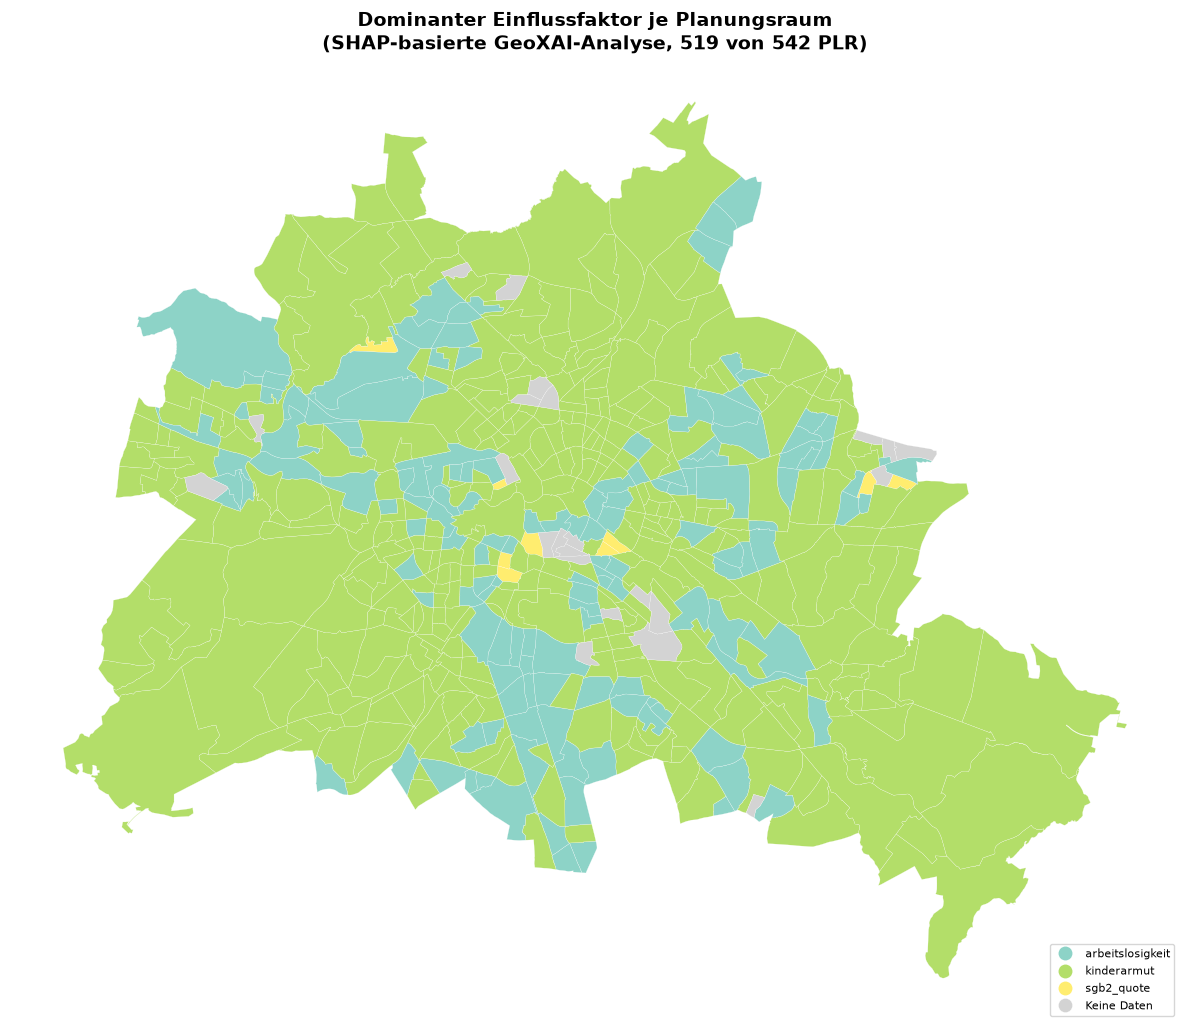

✅ Uebersichtskarte (Flaechen, ganz Berlin) gespeichert!


In [14]:
# ═══════════════════════════════════════════════════════════════
# ZELLE 13: Kartographische Visualisierung (echte Polygone, volle Stadt)
# ═══════════════════════════════════════════════════════════════

gdf_polygone = gpd.read_file('../data/final/plr_polygone.gpkg')
gdf_polygone['plr_id'] = gdf_polygone['plr_id'].astype(str).str.zfill(8)
print(f'✅ {len(gdf_polygone)} Planungsraum-Polygone geladen')

plr_ids_test = test_set.plr_ids[:n_test]

shap_df = pd.DataFrame(shap_mean, columns=[f'shap_{f}' for f in FEATURE_COLS_COMMON])
shap_df['plr_id'] = [str(p) for p in plr_ids_test]

dominant_idx = np.argmax(np.abs(shap_mean), axis=1)
shap_df['dominant_feature'] = [FEATURE_COLS_COMMON[i] for i in dominant_idx]
shap_df['shap_staerke'] = np.max(np.abs(shap_mean), axis=1)

shap_df_agg = shap_df.groupby('plr_id').mean(numeric_only=True).reset_index()
shap_df_dom = shap_df.groupby('plr_id')['dominant_feature'] \
    .agg(lambda x: x.value_counts().idxmax()).reset_index()
shap_df_agg = shap_df_agg.merge(shap_df_dom, on='plr_id')

gdf_shap = gdf_polygone.merge(shap_df_agg, on='plr_id', how='left')
n_covered = gdf_shap['dominant_feature'].notna().sum()
print(f'✅ SHAP-Karten-Datensatz: {n_covered} von {len(gdf_shap)} PLR abgedeckt '
      f'({n_covered/len(gdf_shap)*100:.0f}% der Stadt)')

for feature in FEATURE_COLS_COMMON:
    col = f'shap_{feature}'
    if col not in gdf_shap.columns or gdf_shap[col].isna().all():
        continue

    fig, ax = plt.subplots(figsize=(10, 9))
    gdf_shap.plot(
        column=col, cmap='RdYlGn', legend=True,
        edgecolor='white', linewidth=0.15,
        missing_kwds={'color': 'lightgrey', 'label': 'Keine Daten'},
        ax=ax,
        legend_kwds={'label': f'|SHAP|: {feature}', 'shrink': 0.7}
    )
    ax.set_title(f'Räumlicher Einfluss: {feature}\n'
                 f'auf Status-Index-Prognose (ganz Berlin, {n_covered} PLR)',
                 fontsize=13, fontweight='bold')
    ax.set_axis_off()
    plt.tight_layout()
    plt.savefig(f'../results/06_karte_{feature}.png', dpi=150, bbox_inches='tight')
    plt.close()
    print(f'✅ Flaechenkarte: {feature}')

fig, ax = plt.subplots(figsize=(12, 11))
gdf_shap.plot(
    column='dominant_feature', legend=True, categorical=True,
    cmap='Set3', edgecolor='white', linewidth=0.15,
    missing_kwds={'color': 'lightgrey', 'label': 'Keine Daten'},
    ax=ax, legend_kwds={'loc': 'lower right', 'fontsize': 8}
)
ax.set_title(f'Dominanter Einflussfaktor je Planungsraum\n'
             f'(SHAP-basierte GeoXAI-Analyse, {n_covered} von {len(gdf_shap)} PLR)',
             fontsize=14, fontweight='bold')
ax.set_axis_off()
plt.tight_layout()
plt.savefig('../results/06_karte_dominant.png', dpi=150, bbox_inches='tight')
plt.show()
print('✅ Uebersichtskarte (Flaechen, ganz Berlin) gespeichert!')

Vergleiche Status-Index: 2013 vs. 2023
✅ 519 PLR mit vollstaendiger Zeitreihe 2013-2023


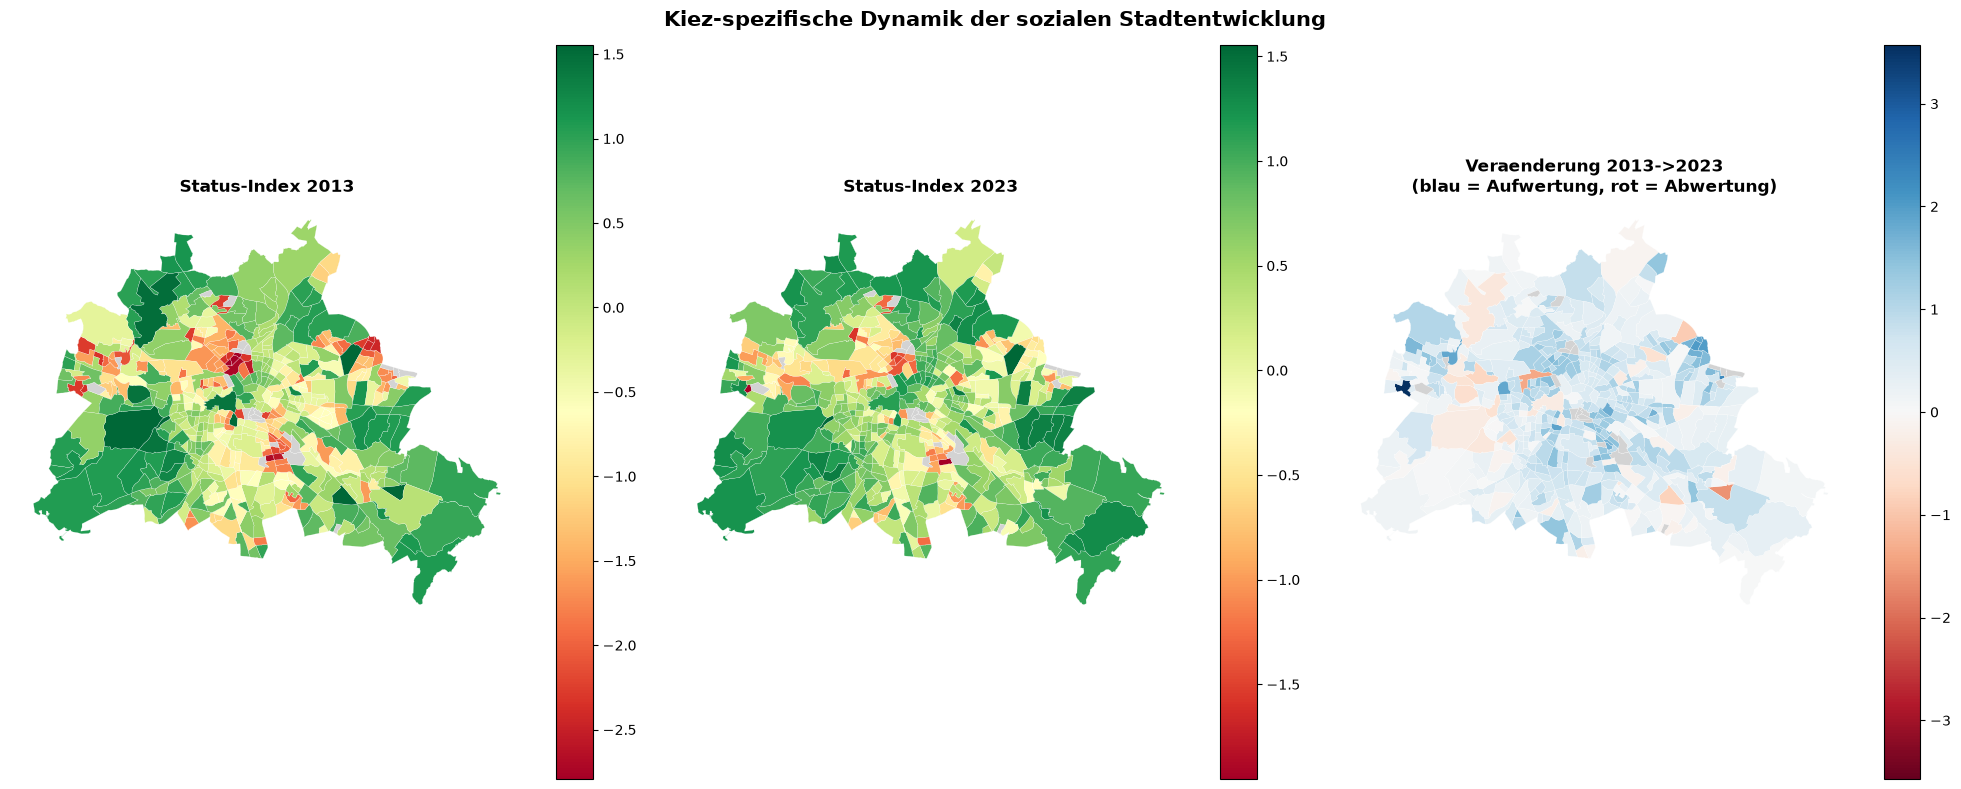

✅ Dynamik-Karte (Zeitverlauf) gespeichert!

📈 Staerkste Aufwertung:
  plr_id  veraenderung
05200525      3.571230
10200421      2.266086
10100103      2.030067
10100104      1.984244
07100206      1.911504

📉 Staerkste Abwertung:
  plr_id  veraenderung
09401433     -1.610708
01200517     -1.384894
11100102     -0.905042
09200715     -0.826002
05300840     -0.754565


In [15]:
# ═══════════════════════════════════════════════════════════════
# ZELLE 13b: Zeitliche Dynamik-Karte (fruehestes vs. spaetestes Jahr)
# ═══════════════════════════════════════════════════════════════

jahre_verfuegbar = sorted(df_full['year'].unique())
jahr_start, jahr_ende = jahre_verfuegbar[0], jahre_verfuegbar[-1]
print(f'Vergleiche Status-Index: {jahr_start} vs. {jahr_ende}')

df_start = df_full[df_full['year']==jahr_start][['plr_id','status_index']] \
    .rename(columns={'status_index':'status_start'})
df_ende  = df_full[df_full['year']==jahr_ende][['plr_id','status_index']] \
    .rename(columns={'status_index':'status_ende'})

df_dynamik = df_start.merge(df_ende, on='plr_id', how='inner')
df_dynamik['veraenderung'] = df_dynamik['status_ende'] - df_dynamik['status_start']

gdf_dynamik = gdf_polygone.merge(df_dynamik, on='plr_id', how='left')
n_dyn = gdf_dynamik['veraenderung'].notna().sum()
print(f'✅ {n_dyn} PLR mit vollstaendiger Zeitreihe {jahr_start}-{jahr_ende}')

fig, axes = plt.subplots(1, 3, figsize=(20, 8))

gdf_dynamik.plot(column='status_start', cmap='RdYlGn', legend=True,
                 edgecolor='white', linewidth=0.15,
                 missing_kwds={'color':'lightgrey'}, ax=axes[0])
axes[0].set_title(f'Status-Index {jahr_start}', fontweight='bold')
axes[0].set_axis_off()

gdf_dynamik.plot(column='status_ende', cmap='RdYlGn', legend=True,
                 edgecolor='white', linewidth=0.15,
                 missing_kwds={'color':'lightgrey'}, ax=axes[1])
axes[1].set_title(f'Status-Index {jahr_ende}', fontweight='bold')
axes[1].set_axis_off()

vmax = max(abs(gdf_dynamik['veraenderung'].min()), abs(gdf_dynamik['veraenderung'].max()))
gdf_dynamik.plot(column='veraenderung', cmap='RdBu', legend=True,
                 vmin=-vmax, vmax=vmax,
                 edgecolor='white', linewidth=0.15,
                 missing_kwds={'color':'lightgrey'}, ax=axes[2])
axes[2].set_title(f'Veraenderung {jahr_start}->{jahr_ende}\n'
                  f'(blau = Aufwertung, rot = Abwertung)', fontweight='bold')
axes[2].set_axis_off()

plt.suptitle('Kiez-spezifische Dynamik der sozialen Stadtentwicklung',
             fontsize=15, fontweight='bold')
plt.tight_layout()
plt.savefig('../results/06_karte_dynamik_zeitverlauf.png', dpi=150, bbox_inches='tight')
plt.show()
print('✅ Dynamik-Karte (Zeitverlauf) gespeichert!')

top_auf = df_dynamik.nlargest(5, 'veraenderung')[['plr_id','veraenderung']]
top_ab  = df_dynamik.nsmallest(5, 'veraenderung')[['plr_id','veraenderung']]
print(f'\n📈 Staerkste Aufwertung:\n{top_auf.to_string(index=False)}')
print(f'\n📉 Staerkste Abwertung:\n{top_ab.to_string(index=False)}')

In [16]:
# ═══════════════════════════════════════════════════════════════
# ZELLE 14: Zusammenfassung
# ═══════════════════════════════════════════════════════════════

print('='*55)
print('NOTEBOOK 06 - XAI ABGESCHLOSSEN!')
print('='*55)
print('\nDatenquelle: ECHTE, areal-interpolierte MSS-Daten')
print('Modell:      lstm_finetuned.pt (Phase 2)')
print(f'Kartenabdeckung: {n_covered} von {len(gdf_shap)} PLR (SHAP)')
print(f'Zeitliche Dynamik: {jahr_start}-{jahr_ende} ({n_dyn} PLR)')
print('\n📊 Top 3 Features:')
print(importance_df[['Rang','Feature','SHAP_Wert']].head(3).to_string(index=False))

print('\n📁 Gespeicherte Dateien:')
for f in sorted(os.listdir('../results/')):
    if any(x in f for x in ['06_','shap','karte','feature']):
        print(f'   {f}')

print('\n✅ Kartographische Aufbereitung vollstaendig:')
print('   - Echte Flaechenkarten (Choroplethen), keine Punkte')
print('   - Ganz Berlin abgedeckt, nicht nur Stichprobe')
print('   - Zeitliche Dynamik sichtbar gemacht (Start- vs. Endjahr)')

NOTEBOOK 06 - XAI ABGESCHLOSSEN!

Datenquelle: ECHTE, areal-interpolierte MSS-Daten
Modell:      lstm_finetuned.pt (Phase 2)
Kartenabdeckung: 519 von 542 PLR (SHAP)
Zeitliche Dynamik: 2013-2023 (519 PLR)

📊 Top 3 Features:
 Rang          Feature  SHAP_Wert
    1      kinderarmut   0.163542
    2 arbeitslosigkeit   0.122658
    3       sgb2_quote   0.062048

📁 Gespeicherte Dateien:
   00_feature_verteilungen.png
   06_karte_arbeitslosigkeit.png
   06_karte_dist_zentrum.png
   06_karte_dominant.png
   06_karte_dynamik_zeitverlauf.png
   06_karte_gruen_anteil.png
   06_karte_kinderarmut.png
   06_karte_laerm_db.png
   06_karte_langzeit_al.png
   06_karte_metro_stations.png
   06_karte_oepnv_stops.png
   06_karte_sgb2_quote.png
   06_karte_status_index.png
   06_karte_status_lag.png
   06_methodenvergleich_shap_tft.png
   06_shap_beeswarm.png
   06_shap_global_bar.png
   06_shap_kiez_vergleich.png
   06_shap_lokal_0.png
   06_shap_lokal_1.png
   06_shap_lokal_2.png
   06_tft_attention_gesa